# P02: dense baseline

The simplest neural network that can look at our paintings: a **dense** (feed-forward) network. It flattens each image
into a list of numbers and does not know which pixels are neighbours. It is our reference point: every other model is
compared with it, with exactly the same data and the same training loop.

Every experiment follows the same four steps:
1. `load_data` (in `utils.py`) prepares the images: shrink, scale, standardise with the train statistics, flatten.
2. We build the model.
3. `fit` (in `utils.py`) trains it and keeps the best epoch on **validation**.
4. `save_result` (in `utils.py`) records the run in `results/`: a pickle whose name contains the date and time, and a row in `experiments.csv`.

**The test set (museum B) is not used in this notebook** (ADR 0003). It is scored once, at the end, on the model we choose.

In [1]:
import math

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import add_test_score, evaluate, fit, load_data, save_result, summary

# Everything we can change in this experiment is here, and is saved with the results.
CONFIG = {
    "model": "dense",
    "image_size": 32,  # images are shrunk to 32 x 32 pixels
    "hidden": 128,  # neurons in the hidden layer
    "epochs": 30,
    "lr": 1e-3,
    "batch_size": 64,
    "weight_decay": 0.0,
    "seed": 0,
}
NAME = "dense_baseline"

## 1. Data

At 32 x 32 pixels with 3 colour channels, each image becomes 3 x 32 x 32 = 3,072 numbers. The classes are balanced, so
guessing at random gives 20%.

In [2]:
data = load_data(size=CONFIG["image_size"])
classes = data["classes"]

print("classes:", classes)
for split in ["train", "val"]:
    counts = torch.bincount(data["y_" + split], minlength=len(classes)).tolist()
    print(f"{split:5s}: X {tuple(data['X_' + split].shape)}, images per class {counts}")
print(f"train pixels after standardisation: mean {data['X_train'].mean().item():.3f}, std {data['X_train'].std().item():.3f}")

classes: ['cityscape', 'landscape', 'portrait', 'religious_painting', 'still_life']
train: X (1920, 3072), images per class [384, 384, 384, 384, 384]
val  : X (480, 3072), images per class [96, 96, 96, 96, 96]
train pixels after standardisation: mean -0.001, std 1.001


## 2. Model

One hidden layer with a ReLU, then 5 outputs (one score per genre). We start with something small on purpose.

In [3]:
n_inputs = data["X_train"].shape[1]


def build_model():
    return nn.Sequential(
        nn.Linear(n_inputs, CONFIG["hidden"]),
        nn.ReLU(),
        nn.Linear(CONFIG["hidden"], len(classes)),
    )


torch.manual_seed(CONFIG["seed"])  # same starting weights every time
model = build_model()
n_params = sum(p.numel() for p in model.parameters())

print(model)
print("parameters:", n_params, "| training images:", len(data["X_train"]))

Sequential(
  (0): Linear(in_features=3072, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=5, bias=True)
)
parameters: 393989 | training images: 1920


## 3. Check before training

With random weights and 5 balanced classes, the loss should be near ln(5) = 1.61 and the accuracy near 20%. If not,
something is wrong with the data or the model, and training would not fix it.

In [4]:
loss0, acc0 = evaluate(model, data["X_train"], data["y_train"])
print(f"before training: loss {loss0:.3f} (ln 5 = {math.log(5):.3f}), accuracy {acc0:.1%} (chance 20%)")

before training: loss 1.639 (ln 5 = 1.609), accuracy 16.4% (chance 20%)


## 4. Training

Adam optimiser, cross-entropy loss, batches of 64 images, data shuffled at every epoch. After each epoch we measure on
the whole train set and on the validation set, and we keep the weights of the epoch with the best validation accuracy.

In [5]:
result = fit(model, data, epochs=CONFIG["epochs"], lr=CONFIG["lr"], batch_size=CONFIG["batch_size"],
             weight_decay=CONFIG["weight_decay"], seed=CONFIG["seed"])

print(f"\nbest validation accuracy {result['best_val_acc']:.1%} at epoch {result['best_epoch']} ({result['seconds']:.0f} s)")

epoch   1 | train loss 1.186 acc 0.512 | val loss 1.568 acc 0.338
epoch   5 | train loss 0.830 acc 0.739 | val loss 1.638 acc 0.371
epoch  10 | train loss 0.497 acc 0.864 | val loss 2.002 acc 0.375
epoch  15 | train loss 0.311 acc 0.915 | val loss 2.346 acc 0.356
epoch  20 | train loss 0.154 acc 0.963 | val loss 2.499 acc 0.377
epoch  25 | train loss 0.078 acc 0.986 | val loss 2.702 acc 0.373
epoch  30 | train loss 0.111 acc 0.977 | val loss 3.117 acc 0.369

best validation accuracy 38.5% at epoch 8 (4 s)


## 5. Learning curves

How to read them: if the train curve keeps improving while the validation curve stops improving or gets worse, the model
is memorising the training images (**overfitting**) instead of learning the genre.

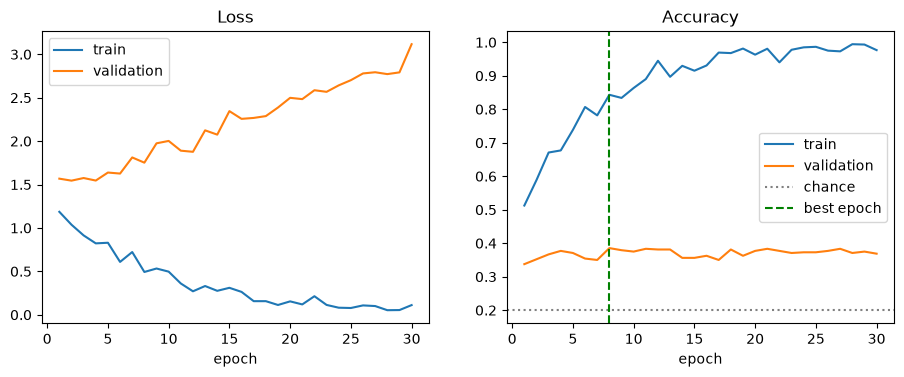

In [6]:
history = result["history"]
epochs = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(epochs, history["train_loss"], label="train")
ax1.plot(epochs, history["val_loss"], label="validation")
ax1.set_title("Loss")
ax1.set_xlabel("epoch")
ax1.legend()

ax2.plot(epochs, history["train_acc"], label="train")
ax2.plot(epochs, history["val_acc"], label="validation")
ax2.axhline(0.2, color="grey", linestyle=":", label="chance")
ax2.axvline(result["best_epoch"], color="green", linestyle="--", label="best epoch")
ax2.set_title("Accuracy")
ax2.set_xlabel("epoch")
ax2.legend()
plt.show()

## 6. Where does it go wrong on validation?

The confusion matrix counts, for each true genre (rows), which genre the model predicted (columns). The diagonal is
what is right.

In [7]:
with torch.no_grad():
    predicted = model.eval()(data["X_val"]).argmax(dim=1)

confusion = pd.crosstab(pd.Series([classes[i] for i in data["y_val"]], name="true genre"),
                        pd.Series([classes[i] for i in predicted], name="predicted"))
confusion = confusion.reindex(index=classes, columns=classes, fill_value=0)

per_class = pd.Series({c: confusion.loc[c, c] / confusion.loc[c].sum() for c in classes}, name="accuracy").round(2)
display(confusion)
display(per_class.to_frame())

predicted,cityscape,landscape,portrait,religious_painting,still_life
true genre,,,,,
cityscape,37,34,10,10,5
landscape,26,50,3,10,7
portrait,10,11,45,20,10
religious_painting,8,6,26,34,22
still_life,13,14,23,27,19


,accuracy
cityscape,0.39
landscape,0.52
portrait,0.47
religious_painting,0.35
still_life,0.20


## 7. Is it just this seed?

Another random start (other initial weights, other shuffling) gives another result. We repeat the training with 5 seeds
to see how much the best validation accuracy moves. Seed 0 is the run above.

In [8]:
val_acc_by_seed = []
for seed in range(5):
    torch.manual_seed(seed)
    run = fit(build_model(), data, epochs=CONFIG["epochs"], lr=CONFIG["lr"], batch_size=CONFIG["batch_size"],
              weight_decay=CONFIG["weight_decay"], seed=seed, verbose=False)
    val_acc_by_seed.append(run["best_val_acc"])
    print(f"seed {seed}: best validation accuracy {run['best_val_acc']:.1%} at epoch {run['best_epoch']}")

accs = pd.Series(val_acc_by_seed)
print(f"\nmean {accs.mean():.1%}, std {accs.std():.1%}, min {accs.min():.1%}, max {accs.max():.1%}")

seed 0: best validation accuracy 38.5% at epoch 8
seed 1: best validation accuracy 38.8% at epoch 7
seed 2: best validation accuracy 37.9% at epoch 23
seed 3: best validation accuracy 39.6% at epoch 19
seed 4: best validation accuracy 40.2% at epoch 13

mean 39.0%, std 0.9%, min 37.9%, max 40.2%


## 8. Save the result

The pickle holds the settings, the curves and the validation scores. Its name contains the date and time, so a run never
overwrites an earlier one. The weights go in a `.pt` file next to it (ignored by Git). One row is also added to
`results/experiments.csv`: the settings and the scores of every run in one table. The test columns of that row stay empty
for now: the test set is used once, when the model is final.

In [9]:
stem = save_result(NAME, {
    "config": CONFIG,
    "n_params": n_params,
    "history": result["history"],
    "best_epoch": result["best_epoch"],
    "best_val_acc": result["best_val_acc"],
    "seconds": result["seconds"],
    "classes": classes,
    "val_confusion": confusion,
    "val_acc_by_seed": val_acc_by_seed,
}, weights=result["best_weights"])

summary()  # one row per saved experiment: this table will grow as we add models

saved results/dense_baseline_2026-10-21_17-50-22.pkl and added a row to results/experiments.csv


,date,name,model,image_size,hidden,epochs,lr,batch_size,weight_decay,seed,n_params,best_epoch,best_val_acc,val_acc_mean,val_acc_std,test_acc,test_loss,test_date,seconds,file
0,2026-10-21 17:29:52,dense_baseline,dense,32,128,30,0.001,64,0.0,0,393989,8,0.3854,0.39,0.009,NaN,NaN,NaN,4,dense_baseline_2026-10-21_17-29-52
1,2026-10-21 17:50:22,dense_baseline,dense,32,128,30,0.001,64,0.0,0,393989,8,0.3854,0.39,0.009,NaN,NaN,NaN,4,dense_baseline_2026-10-21_17-50-22


## 9. Score on the test set (only when this model is final)

Museum B is used once per model (ADR 0003). `add_test_score` loads the weights saved with this run, scores them on the test
set, and fills `test_acc`, `test_loss` and `test_date` in the run's row of `results/experiments.csv`. It refuses to score
the same run twice. Leave `TEST_NOW` at `False` while we are still experimenting.

In [10]:
TEST_NOW = False  # set to True only when this model is final, then run this cell once

if TEST_NOW:
    test_data = load_data(size=CONFIG["image_size"], splits=("train", "val", "test"))
    add_test_score(stem, build_model(), test_data)

## What we see

- **The baseline to beat: about 39% validation accuracy** (38.5% for seed 0 at epoch 8, 39.0% on average over 5 seeds), against 20% by chance. With 480 validation images, the
  uncertainty is about +/- 4 points, so differences smaller than that are not evidence.
- **It overfits massively.** Train accuracy climbs to 98% while validation stays around 35-38% from the first epochs on, and
  the validation loss rises from 1.57 (epoch 1) to 3.12 (epoch 30). The network memorises the 1,920 training images instead
  of learning what a genre looks like. Keeping the best epoch limits the damage but does not cure it.
- **Some genres are harder.** Landscape (52%) and portrait (47%) are best. Still life is at chance level (20%): it is mostly
  predicted as religious painting (27 of 96) or portrait (23 of 96). We have not tested why. A guess is that a dense
  network only sees the layout of colours, and these genres share dark backgrounds.
- **It is not bad luck.** Over 5 seeds the best validation accuracy goes from 37.9% to 40.2% (std 0.9): always far above the 20%
  of chance and far below the training accuracy. The seed matters less than the +/- 4 points of uncertainty of 480 images.
  Since we keep the best of 30 epochs, these scores are slightly optimistic.

Next experiments (all in notebooks, all saved with `save_result`): regularisation against the overfitting (weight decay,
dropout), other image sizes, then a pretrained ResNet.